**KLON REPOSITORI GITHUB**

In [ ]:
# Klon repositori GitHub
!git clone https://github.com/Abonia1/YOLOv8-Fire-and-Smoke-Detection.git
%cd YOLOv8-Fire-and-Smoke-Detection

# Pasang pustaka ultralytics
!pip install ultralytics

Cloning into 'YOLOv8-Fire-and-Smoke-Detection'...
remote: Enumerating objects: 1961, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 1961 (delta 7), reused 5 (delta 5), pack-reused 1952 (from 2)
Receiving objects: 100% (1961/1961), 256.45 MiB | 39.04 MiB/s, done.
Resolving deltas: 100% (11/11), done.
Updating files: 100% (2069/2069), done.
/content/YOLOv8-Fire-and-Smoke-Detection
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 1.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
!ls

 datasets    runs
 demo.gif   'train-yolov8-early-fire&smoke-detection-on-custom-dataset.ipynb'
 demo.mp4    yolov8n.pt
 output      yolov8s.pt
 README.md


DEMO

In [ ]:
# from ultralytics import YOLO

# # Load model dari repositori
# model = YOLO('yolov8s.pt')

# # Jalankan prediksi pada video demo.mp4
# results = model.predict(source='demo.mp4', save=True, conf=0.25)

In [ ]:
# from google.colab import files

# # Sesuaikan nama berkas jika formatnya .mp4 atau .avi
# files.download('/content/YOLOv8-Fire-and-Smoke-Detection/runs/detect/predict-2/demo.avi')

Ambil Dataset

In [ ]:
!pip install roboflow

from roboflow import Roboflow
# Inisialisasi API Roboflow
rf = Roboflow(api_key="XkVVGlm6oxQrj6njEbNT")

# 1. Unduh Dataset Pertama
ds1 = rf.workspace("custom-thxhn").project("fire-wrpgm").version(8).download("yolov8")

# 2. Unduh Dataset Kedua (Ganti sesuai nama workspace, project, dan versi yang kamu pilih)
ds2 = rf.workspace("hanin-putri-sholiha").project("fire-dataset-for-yolov8-deupo-igc8s").version(1).download("yolov8")

# 3. Unduh Dataset Ketiga (Ganti sesuai nama workspace, project, dan versi yang kamu pilih)
ds3 = rf.workspace("hanin-putri-sholiha").project("building-fire-vcieb-63sl2").version(1).download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.5 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-8 in yolov8:: 100%|██████████| 1970/1970 [00:00<00:00, 10644.44it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fire-Dataset-for-YOLOv8-1 in yolov8:: 100%|██████████| 7995/7995 [00:01<00:00, 7676.30it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to building-fire-1 in yolov8:: 100%|██████████| 4004/4004 [00:00<00:00, 4706.25it/s]


Simpan Dataset ke Drive

In [ ]:
import os
import shutil
from google.colab import drive

# 1. Pastikan Google Drive terhubung
drive.mount("/content/drive")

# 2. Tentukan folder master permanen di Google Drive
master_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"

# Mengambil lokasi folder sementara Roboflow
source_datasets = [ds1.location, ds2.location, ds3.location]

# Buat struktur folder master di Google Drive
for split in ["train", "val"]:
  os.makedirs(f"{master_dir}/images/{split}", exist_ok=True)
  os.makedirs(f"{master_dir}/labels/{split}", exist_ok=True)

# 3. Pindahkan file ke Drive dengan penamaan unik (mencegah bentrok)
for ds_idx, src_path in enumerate(source_datasets):
  if not os.path.exists(src_path):
    continue

  print(f"Memproses dan memindahkan {src_path} ke Google Drive...")
  for split in ["train", "val"]:
    img_src = os.path.join(src_path, split, "images")
    lbl_src = os.path.join(src_path, split, "labels")

    if os.path.exists(img_src):
      for file in os.listdir(img_src):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
          new_filename = f"ds{ds_idx+1}_{file}"

          # Salin foto ke Drive
          shutil.copy(
              os.path.join(img_src, file),
              os.path.join(master_dir, "images", split, new_filename),
          )

          # Salin label .txt ke Drive (jika ada)
          txt_file = os.path.splitext(file)[0] + ".txt"
          if os.path.exists(os.path.join(lbl_src, txt_file)):
            new_txtname = f"ds{ds_idx+1}_{txt_file}"
            shutil.copy(
                os.path.join(lbl_src, txt_file),
                os.path.join(master_dir, "labels", split, new_txtname),
            )

  # 4. HAPUS FOLDER SEMENTARA DI COLAB LOKAL
  shutil.rmtree(src_path)
  print(f"✅ Folder sementara {src_path} berhasil dihapus dari Colab lokal.")

print("\n🎉 Seluruh dataset Roboflow telah tersimpan permanen di Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memproses dan memindahkan /content/YOLOv8-Fire-and-Smoke-Detection/fire-8 ke Google Drive...
✅ Folder sementara /content/YOLOv8-Fire-and-Smoke-Detection/fire-8 berhasil dihapus dari Colab lokal.
Memproses dan memindahkan /content/YOLOv8-Fire-and-Smoke-Detection/Fire-Dataset-for-YOLOv8-1 ke Google Drive...
✅ Folder sementara /content/YOLOv8-Fire-and-Smoke-Detection/Fire-Dataset-for-YOLOv8-1 berhasil dihapus dari Colab lokal.
Memproses dan memindahkan /content/YOLOv8-Fire-and-Smoke-Detection/building-fire-1 ke Google Drive...
✅ Folder sementara /content/YOLOv8-Fire-and-Smoke-Detection/building-fire-1 berhasil dihapus dari Colab lokal.

🎉 Seluruh dataset Roboflow telah tersimpan permanen di Google Drive!


Membuat data.yaml

In [ ]:
import os
import yaml
from ultralytics import YOLO

# 1. Tentukan lokasi folder master & path data.yaml
master_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"
yaml_master_path = os.path.join(master_dir, "data.yaml")

# 2. Buat konfigurasi data.yaml
config = {
    "path": master_dir,
    "train": "images/train",
    "val": "images/val",
    "nc": 2,
    "names": {0: "fire", 1: "smoke"},
}

# 3. Tulis berkas data.yaml ke Google Drive
os.makedirs(master_dir, exist_ok=True)
with open(yaml_master_path, "w") as f:
  yaml.dump(config, f, default_flow_style=False)

print(f"✅ Berkas data.yaml berhasil dibuat di: {yaml_master_path}\n")

Memastikan variabel kelas

In [ ]:
!cat "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master/data.yaml"

cat: '/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master/data.yaml': No such file or directory


Split Data di Drive

In [ ]:
import os
import random
import shutil

master_dir = (
    "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"
)

train_img_dir = os.path.join(master_dir, "images/train")
train_lbl_dir = os.path.join(master_dir, "labels/train")
val_img_dir = os.path.join(master_dir, "images/val")
val_lbl_dir = os.path.join(master_dir, "labels/val")

# Buat folder val jika belum ada
os.makedirs(val_img_dir, exist_ok=True)
os.makedirs(val_lbl_dir, exist_ok=True)

# Ambil seluruh daftar gambar di folder train
images = [
    f
    for f in os.listdir(train_img_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Hitung 20% data untuk dikirim ke folder val
num_val = int(len(images) * 0.2)
val_images = random.sample(images, num_val)

print(
    f"Memindahkan {num_val} gambar & label dari 'train' ke 'val' secara"
    " otomatis..."
)

for img_name in val_images:
  # Pindahkan file Gambar
  shutil.move(
      os.path.join(train_img_dir, img_name),
      os.path.join(val_img_dir, img_name),
  )

  # Pindahkan file Label (.txt) jika ada
  txt_name = os.path.splitext(img_name)[0] + ".txt"
  txt_src = os.path.join(train_lbl_dir, txt_name)
  if os.path.exists(txt_src):
    shutil.move(txt_src, os.path.join(val_lbl_dir, txt_name))

print(
    f"✅ Selesai! Folder 'val' sekarang sudah terisi {len(os.listdir(val_img_dir))} gambar."
)

Diagnosa Distribusi Class ID Saat Ini

In [ ]:
import os
from collections import Counter

master_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"
label_dir = os.path.join(master_dir, "labels")

class_counts = Counter()
ds_class_counts = {"ds1": Counter(), "ds2": Counter(), "ds3": Counter()}

for root, _, files in os.walk(label_dir):
  for file in files:
    if file.endswith(".txt"):
      prefix = file[:3] if file[:3] in ds_class_counts else "other"
      with open(os.path.join(root, file), "r") as f:
        for line in f:
          parts = line.strip().split()
          if parts:
            cid = parts[0]
            class_counts[cid] += 1
            if prefix in ds_class_counts:
              ds_class_counts[prefix][cid] += 1

print("📊 Distribusi Class ID di dataset_master:")
for cid, count in sorted(class_counts.items()):
  print(f" - Class ID '{cid}': {count} bounding box")

print("\n🔍 Rincian per Dataset Origin:")
for ds, counts in ds_class_counts.items():
  print(f" - {ds}: {dict(counts)}")

Pembersihan Dataset

In [ ]:
import os

master_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"
label_dir = os.path.join(master_dir, "labels")

# Hanya menyimpan Class ID 0 (fire) dan 1 (smoke)
valid_class_ids = ["0", "1"]

cleaned_files = 0
removed_boxes = 0

for root, _, files in os.walk(label_dir):
  for file in files:
    if file.endswith(".txt"):
      file_path = os.path.join(root, file)
      new_lines = []

      with open(file_path, "r") as f:
        lines = f.readlines()

      for line in lines:
        parts = line.strip().split()
        if parts:
          class_id = parts[0]
          if class_id in valid_class_ids:
            new_lines.append(line)
          else:
            removed_boxes += 1

      with open(file_path, "w") as f:
        f.writelines(new_lines)

      cleaned_files += 1

print(f"✅ Pembersihan selesai pada {cleaned_files} berkas label.")
print(
    f"🗑️ Berhasil membuang {removed_boxes} bounding box Class ID '2' (default)."
)

✅ Pembersihan selesai pada 0 berkas label.
🗑️ Berhasil membuang 0 bounding box Class ID '2' (default).


Perbarui data.yaml

In [ ]:
# Pasang pustaka ultralytics
!pip install ultralytics

In [ ]:
import os
import yaml
from ultralytics import YOLO

master_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master"
yaml_master_path = os.path.join(master_dir, "data.yaml")

# Pastikan data.yaml hanya berisi 2 kelas
clean_config = {
    "path": master_dir,
    "train": "images/train",
    "val": "images/val",
    "nc": 2,
    "names": {0: "fire", 1: "smoke"},
}

with open(yaml_master_path, "w") as f:
  yaml.dump(clean_config, f, default_flow_style=False)

print(
    "✅ data.yaml berhasil diperbarui (Hanya 2 kelas: 0=fire, 1=smoke)"
)

**TRAINING**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Jalankan Training fire_smoke_v3

import os
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/yolov8s.pt")

# Jalankan training
results = model.train(
    data=yaml_master_path,
    epochs=50,
    imgsz=640,
    batch=16,
    name="fire_smoke_v3",
)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/dataset_master/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/yolov8s.p

Menyimpan Model Training ke Drive

In [ ]:
import os
import shutil
from glob import glob

# Cari file best.pt secara otomatis di folder /content
found_files = glob("/content/**/fire_smoke_v3/**/best.pt", recursive=True)

if not found_files:
  # Pengecekan cadangan jika direktori berbeda
  found_files = glob("/content/**/weights/best.pt", recursive=True)

if found_files:
  source_weights = found_files[-1]  # Mengambil file best.pt terbaru
  drive_weights = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/best_v3.pt"

  os.makedirs(os.path.dirname(drive_weights), exist_ok=True)
  shutil.copy(source_weights, drive_weights)

  print(f"📍 Lokasi asal ditemukannya berkas: {source_weights}")
  print(f"✅ Berhasil disalin ke Google Drive: {drive_weights}")
else:
  print(
      "❌ Berkas best.pt belum ditemukan. Pastikan proses training sudah selesai"
      " hingga epoch terakhir."
  )

menggunakan model best_v3_old.pt dan menjalankan perintah berikut

In [2]:
# 1. Mount Google Drive
import os
from google.colab import drive

drive.mount("/content/drive")

# 2. Install Library Utama
!pip install -q ultralytics sahi scikit-learn opencv-python pyyaml

Mounted at /content/drive


In [ ]:
# # memperbarui metadata model best_v3_old.pt

# import os
# import torch
# from ultralytics import YOLO

# base_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv"
# v3_path = os.path.join(base_dir, "best_v3_old.pt")
# fixed_path = os.path.join(base_dir, "best_v3.pt")

# # 1. Load checkpoint PyTorch dari file best_v3.pt
# ckpt = torch.load(v3_path, map_location="cpu", weights_only=False)

# # 2. Ubah metadata daftar nama kelas (names) menjadi 'fire'
# if "model" in ckpt and hasattr(ckpt["model"], "names"):
#     # Mengubah seluruh ID kelas (0 dan 1) menjadi 'fire'
#     ckpt["model"].names = {
#         i: "fire" for i in range(len(ckpt["model"].names))
#     }

# if "names" in ckpt:
#     ckpt["names"] = {i: "fire" for i in range(len(ckpt["names"]))}

# # 3. Simpan sebagai file model .pt baru
# torch.save(ckpt, fixed_path)
# print(f"✅ Berkas model baru berhasil dibuat: {fixed_path}")

# # 4. Verifikasi dengan memanggil model menggunakan pustaka YOLO standar
# test_model = YOLO(fixed_path)
# print("Daftar kelas terdeteksi pada model baru:", test_model.names)

✅ Berkas model baru berhasil dibuat: /content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/best_v3.pt
Daftar kelas terdeteksi pada model baru: {0: 'fire', 1: 'fire'}


Penulisan fire_pipeline.py

In [7]:
%%writefile "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/fire_pipeline.py"
import os
import json
import cv2
import numpy as np
from sklearn.cluster import DBSCAN
from ultralytics import YOLO

def process_fire_telemetry(
    video_input_path,
    model_path="/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/best_v3.pt",
    output_dir="/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/output",
    conf_threshold=0.15,
    eps_distance=120
):
    os.makedirs(output_dir, exist_ok=True)

    filename = os.path.splitext(os.path.basename(video_input_path))[0]
    video_output_path = os.path.join(output_dir, f"{filename}_telemetry2.mp4")
    json_output_path = os.path.join(output_dir, f"{filename}_telemetry2.json")

    model = YOLO(model_path)
    cap = cv2.VideoCapture(video_input_path)
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps    = int(cap.get(cv2.CAP_PROP_FPS)) or 30

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out_video = cv2.VideoWriter(video_output_path, fourcc, fps, (width, height))

    COLOR_MAP = {
        2: (0, 165, 255),     # Oranye
        3: (0, 0, 255)        # Merah
    }

    json_output_data = []
    frame_idx = 0
    level3_start_sec = None

    print(f"⏳ Memproses video '{filename}' dan membuat telemetri...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        frame_idx += 1
        current_sec = frame_idx / fps
        results = model.predict(frame, conf=conf_threshold, verbose=False)[0]

        frame_info = {
            "frame": frame_idx,
            "total_detections": 0,
            "total_clusters": 0,
            "cluster_level": "Aman",
            "detections": []
        }

        if results.boxes is not None and len(results.boxes) > 0:
            boxes = results.boxes.xyxy.cpu().numpy()
            confs = results.boxes.conf.cpu().numpy()

            centroids = []
            total_fire_area = 0

            for box in boxes:
                cx = (box[0] + box[2]) / 2
                cy = (box[1] + box[3]) / 2
                area = (box[2] - box[0]) * (box[3] - box[1])
                centroids.append([cx, cy])
                total_fire_area += area

            centroids = np.array(centroids)

            if len(centroids) > 1:
                db = DBSCAN(eps=eps_distance, min_samples=1).fit(centroids)
                cluster_labels = db.labels_
            else:
                cluster_labels = np.array([0])

            num_clusters = len(set(cluster_labels))

            if total_fire_area > 40000:
                level_code = 3
                if level3_start_sec is None:
                    level3_start_sec = current_sec

                if (current_sec - level3_start_sec) > 5.0:
                    level_name = "Level 3 (Bahaya)"
                else:
                    level_name = "Level 3"
            elif total_fire_area > 10000:
                level_code = 2
                level_name = "Level 2"
                level3_start_sec = None
            else:
                level_code = 1
                level_name = "Level 1 (Aman)"
                level3_start_sec = None

            frame_info["total_detections"] = len(boxes)
            frame_info["total_clusters"] = num_clusters
            frame_info["cluster_level"] = level_name

            for idx, box in enumerate(boxes):
                xmin, ymin, xmax, ymax = map(int, box)
                c_id = int(cluster_labels[idx])
                cf = float(confs[idx])

                frame_info["detections"].append({
                    "class_name": "fire",
                    "confidence": round(cf, 4),
                    "cluster_id": c_id,
                    "bbox": [xmin, ymin, xmax, ymax]
                })

            if level_code in [2, 3]:
                box_color = COLOR_MAP[level_code]
                for det in frame_info["detections"]:
                    xmin, ymin, xmax, ymax = det["bbox"]
                    c_id = det["cluster_id"]
                    cf = det["confidence"]
                    cv2.rectangle(frame, (xmin, ymin), (xmax, ymax), box_color, 2)
                    label_text = f"fire | Cluster {c_id} | {cf:.2f}"
                    cv2.putText(frame, label_text, (xmin, max(ymin - 10, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, box_color, 2)

                banner_text = f"STATUS: {level_name.upper()}"
                cv2.rectangle(frame, (10, 10), (450, 50), (0, 0, 0), -1)
                cv2.putText(frame, banner_text, (20, 38),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, box_color, 2)
            else:
                cv2.rectangle(frame, (10, 10), (280, 50), (0, 0, 0), -1)
                cv2.putText(frame, "STATUS: AMAN", (20, 38),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        else:
            level3_start_sec = None
            cv2.rectangle(frame, (10, 10), (280, 50), (0, 0, 0), -1)
            cv2.putText(frame, "STATUS: AMAN", (20, 38),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

        json_output_data.append(frame_info)
        out_video.write(frame)

    cap.release()
    out_video.release()

    with open(json_output_path, "w") as f:
        json.dump(json_output_data, f, indent=4)

    print(f"🎉 Selesai!")
    print(f"🎥 Video tersimpan di: {video_output_path}")
    print(f"📄 JSON tersimpan di: {json_output_path}")
    return video_output_path, json_output_path

Overwriting /content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/fire_pipeline.py


In [8]:
# CATATAN: Jika Anda mendapatkan error 'circular import' / 'partially initialized module torch',
# Silakan klik menu 'Runtime' -> 'Restart session' di bagian atas Colab, lalu jalankan kembali cell ini.

import sys
sys.path.append("/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv")
from fire_pipeline import process_fire_telemetry

# Panggil fungsi dengan 1 baris saja!
process_fire_telemetry("/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/test-fire4.mp4")

⏳ Memproses video 'test-fire4' dan membuat telemetri...
🎉 Selesai!
🎥 Video tersimpan di: /content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/output/test-fire4_telemetry2.mp4
📄 JSON tersimpan di: /content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/output/test-fire4_telemetry2.json


('/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/output/test-fire4_telemetry2.mp4',
 '/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/output/test-fire4_telemetry2.json')

**Kode Pembaruan Modul fire_pipeline.py untuk LIVE CCTV**

(fire_pipeline_live.py)

In [9]:
import os

live_pipeline_code = """import os
import time
import json
import cv2
import numpy as np
import requests
from sklearn.cluster import DBSCAN
from ultralytics import YOLO
from IPython.display import display, Image

def _run_detection(frame, model, conf_threshold, eps_distance):
    results = model.predict(frame, conf=conf_threshold, verbose=False)[0]
    payload = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "total_detections": 0,
        "total_clusters": 0,
        "cluster_level": "Aman",
        "level_code": 1,
        "detections": []
    }

    if results.boxes is not None and len(results.boxes) > 0:
        boxes = results.boxes.xyxy.cpu().numpy()
        confs = results.boxes.conf.cpu().numpy()

        centroids = []
        total_fire_area = 0

        for box in boxes:
            cx = (box[0] + box[2]) / 2
            cy = (box[1] + box[3]) / 2
            area = (box[2] - box[0]) * (box[3] - box[1])
            centroids.append([cx, cy])
            total_fire_area += area

        centroids = np.array(centroids)

        if len(centroids) > 1:
            db = DBSCAN(eps=eps_distance, min_samples=1).fit(centroids)
            cluster_labels = db.labels_
        else:
            cluster_labels = np.array([0])

        num_clusters = len(set(cluster_labels))

        if total_fire_area > 40000:
            level_name = "Level 3"
            level_code = 3
        elif total_fire_area > 10000:
            level_name = "Level 2"
            level_code = 2
        else:
            level_name = "Level 1 (Aman)"
            level_code = 1

        payload["total_detections"] = len(boxes)
        payload["total_clusters"] = num_clusters
        payload["cluster_level"] = level_name
        payload["level_code"] = level_code

        for idx, box in enumerate(boxes):
            xmin, ymin, xmax, ymax = map(int, box)
            c_id = int(cluster_labels[idx])
            cf = float(confs[idx])

            payload["detections"].append({
                "class_name": "fire",
                "confidence": round(cf, 4),
                "cluster_id": c_id,
                "bbox": [xmin, ymin, xmax, ymax]
            })

    return payload, results

# 1. OUTPUT LOG TEKS PER-FRAME
def process_live_cctv_logs(
    cctv_url,
    model_path="/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/best_v3.pt",
    dashboard_api_url=None,
    conf_threshold=0.45,
    eps_distance=120,
    skip_frames=1
):
    model = YOLO(model_path)
    cap = cv2.VideoCapture(cctv_url)
    cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)

    if not cap.isOpened():
        print("❌ Gagal terhubung ke CCTV.")
        return

    print("🟢 Memulai Mode Log Teks Per-Frame...")
    frame_count = 0
    level3_start_time = None

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                time.sleep(1)
                cap = cv2.VideoCapture(cctv_url)
                continue

            frame_count += 1
            if frame_count % (skip_frames + 1) != 0:
                continue

            payload, _ = _run_detection(frame, model, conf_threshold, eps_distance)

            # Verification 5 detik berurutan untuk Level 3
            if payload["level_code"] == 3:
                now = time.time()
                if level3_start_time is None:
                    level3_start_time = now

                elapsed = now - level3_start_time
                if elapsed > 5.0:
                    payload["cluster_level"] = "Level 3 (Bahaya)"
                else:
                    payload["cluster_level"] = "Level 3"
            else:
                level3_start_time = None

            if payload["level_code"] in [2, 3]:
                print(f"🔥 [{payload['timestamp']}] DETEKSI: {payload['total_detections']} Titik Api | Status: {payload['cluster_level']}")
            else:
                print(f"🟢 [{payload['timestamp']}] Status: Aman (Tidak Ada Api / Level 1)")

            if dashboard_api_url and payload["level_code"] in [2, 3]:
                try:
                    requests.post(dashboard_api_url, json=payload, timeout=0.5)
                except Exception:
                    pass

    except KeyboardInterrupt:
        print("\\n🛑 Pengawasan dihentikan.")
    finally:
        cap.release()

# 2. OUTPUT DISPLAY VIDEO STREAMING
def process_live_cctv_video(
    cctv_url,
    model_path="/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/best_v3.pt",
    dashboard_api_url=None,
    conf_threshold=0.45,
    eps_distance=120,
    skip_frames=1
):
    model = YOLO(model_path)
    cap = cv2.VideoCapture(cctv_url)
    cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)

    if not cap.isOpened():
        print("❌ Gagal terhubung ke CCTV.")
        return

    print("🟢 Memulai Live Video Stream (Smooth Mode)...")
    COLOR_MAP = {
        2: (0, 165, 255), # Oranye (Level 2)
        3: (0, 0, 255)    # Merah (Level 3)
    }

    frame_count = 0
    display_handle = None
    level3_start_time = None

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                time.sleep(1)
                cap = cv2.VideoCapture(cctv_url)
                continue

            frame_count += 1
            if frame_count % (skip_frames + 1) != 0:
                continue

            payload, _ = _run_detection(frame, model, conf_threshold, eps_distance)

            # Verification 5 detik berurutan untuk Level 3
            if payload["level_code"] == 3:
                now = time.time()
                if level3_start_time is None:
                    level3_start_time = now

                elapsed = now - level3_start_time
                if elapsed > 5.0:
                    payload["cluster_level"] = "Level 3 (Bahaya)"
                else:
                    payload["cluster_level"] = "Level 3"
            else:
                level3_start_time = None

            if payload["level_code"] in [2, 3]:
                box_color = COLOR_MAP[payload["level_code"]]
                for det in payload["detections"]:
                    xmin, ymin, xmax, ymax = det["bbox"]
                    c_id = det["cluster_id"]
                    cf = det["confidence"]

                    cv2.rectangle(frame, (xmin, ymin), (xmax, ymax), box_color, 2)
                    label_text = f"fire | Cluster {c_id} | {cf:.2f}"
                    cv2.putText(frame, label_text, (xmin, max(ymin - 10, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, box_color, 2)

                banner_text = f"STATUS: {payload['cluster_level'].upper()}"
                cv2.rectangle(frame, (10, 10), (450, 50), (0, 0, 0), -1)
                cv2.putText(frame, banner_text, (20, 38),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, box_color, 2)
            else:
                cv2.rectangle(frame, (10, 10), (280, 50), (0, 0, 0), -1)
                cv2.putText(frame, "STATUS: AMAN", (20, 38),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

            resized_frame = cv2.resize(frame, (640, 360))
            encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), 75]
            _, buffer = cv2.imencode('.jpg', resized_frame, encode_param)

            image_widget = Image(data=buffer.tobytes())

            if display_handle is None:
                display_handle = display(image_widget, display_id=True)
            else:
                display_handle.update(image_widget)

            if dashboard_api_url and payload["level_code"] in [2, 3]:
                try:
                    requests.post(dashboard_api_url, json=payload, timeout=0.5)
                except Exception:
                    pass

    except KeyboardInterrupt:
        print("\\n🛑 Pengawasan dihentikan.")
    finally:
        cap.release()
"""

file_path = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/fire_pipeline_live.py"
with open(file_path, "w") as f:
    f.write(live_pipeline_code)

print(f"✅ Modul berhasil diperbarui dengan logika batas 5 detik: {file_path}")

✅ Modul berhasil diperbarui dengan logika batas 5 detik: /content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/fire_pipeline_live.py


In [ ]:
!pip install matplotlib-venn

Eksekusi Output Teks

In [10]:
import sys
import importlib

sys.path.append("/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv")

# (Memaksa Python memuat ulang modul jika sudah pernah diimpor sebelumnya)
if "fire_pipeline_live" in sys.modules:
    importlib.reload(sys.modules["fire_pipeline_live"])

from fire_pipeline_live import process_live_cctv_logs

# 1. Masukkan URL RTSP/HLS CCTV
# CCTV_URL = "https://test-streams.mux.dev/x36xhzz/x36xhzz.m3u8"
CCTV_URL = (
    "https://restreamer2.kotabogor.go.id/memfs/1bcb7d49-9573-4d87-9e74-b6b1a4cfdcfc.m3u8"
)

# 2. (Opsional) URL Endpoint API Dashboard Admin Anda
# API_DASHBOARD = "https://api.dashboard-admin.com/v1/cctv-alerts"
API_DASHBOARD = None

# 3. Hanya menampilkan log teks per frame di konsol
process_live_cctv_logs(cctv_url=CCTV_URL, dashboard_api_url=API_DASHBOARD)

🟢 Memulai Mode Log Teks Per-Frame...
🟢 [2026-11-02 22:51:27] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:27] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:27] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:27] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:27] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:51:28] Status: Aman (Tidak Ada Api / Level 1)
🟢 [2026-11-02 22:5

Eksekusi Output Video Streaming

🟢 Memulai Live Video Stream (Smooth Mode)...


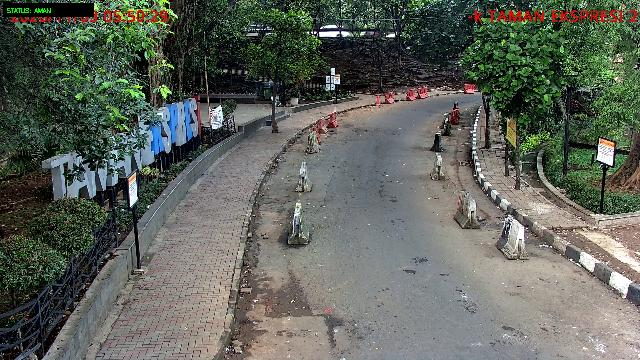


🛑 Pengawasan dihentikan.


In [11]:
import sys
import importlib

sys.path.append("/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv")

# (Memaksa Python memuat ulang modul jika sudah pernah diimpor sebelumnya)
if "fire_pipeline_live" in sys.modules:
    importlib.reload(sys.modules["fire_pipeline_live"])

from fire_pipeline_live import process_live_cctv_video

# 1. Masukkan URL RTSP/HLS CCTV
# CCTV_URL = "https://test-streams.mux.dev/x36xhzz/x36xhzz.m3u8"
CCTV_URL = (
    "https://restreamer2.kotabogor.go.id/memfs/1bcb7d49-9573-4d87-9e74-b6b1a4cfdcfc.m3u8"
)

# 2. (Opsional) URL Endpoint API Dashboard Admin Anda
# API_DASHBOARD = "https://api.dashboard-admin.com/v1/cctv-alerts"
API_DASHBOARD = None

# 3. Menampilkan tayangan video langsung dengan bounding box
process_live_cctv_video(cctv_url=CCTV_URL, conf_threshold=0.45)

Mengambil Sample Kondisi Normal (frame)

In [ ]:
# import cv2

# cctv_url = "https://restreamer5.kotabogor.go.id/memfs/a4e728ef-9bbc-4c89-a303-9d4a160cb940.m3u8"
# cap = cv2.VideoCapture(cctv_url)

# if not cap.isOpened():
#     print("Gagal terhubung ke URL CCTV. Periksa kembali tautannya.")
# else:
#     ret, frame = cap.read()
#     if ret:
#         print(
#             "Koneksi berhasil! Gambar berhasil dibaca dengan ukuran:",
#             frame.shape,
#         )
#     else:
#         print("Terhubung ke stream, tetapi gagal mengambil frame gambar.")

# cap.release()

In [ ]:
# import cv2
# import time
# import os

# # Ganti dengan URL stream CCTV (RTSP, .m3u8, atau URL IP stream dari link HTML)
# cctv_url = "https://restreamer5.kotabogor.go.id/memfs/a4e728ef-9bbc-4c89-a303-9d4a160cb940.m3u8"
# output_folder = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/negative_samples/images"
# os.makedirs(output_folder, exist_ok=True)

# cap = cv2.VideoCapture(cctv_url)
# saved_count = 0
# target_frames = 50  # Ambil 50 gambar per sesi

# print("Menghubungkan ke stream CCTV...")
# while cap.isOpened() and saved_count < target_frames:
#     ret, frame = cap.read()
#     if not ret:
#         print("Gagal membaca stream. Pastikan URL stream sudah benar.")
#         break

#     # Simpan berkas gambar .jpg secara langsung
#     filename = f"{output_folder}/cctv_sample_{int(time.time())}_{saved_count:03d}.jpg"
#     cv2.imwrite(filename, frame)
#     saved_count += 1

#     # Jeda 0.5 detik antar gambar
#     time.sleep(0.5)

# cap.release()
# print(f"Selesai! {saved_count} foto tersimpan langsung di folder '{output_folder}'.")

In [ ]:
# import os
# from glob import glob

# img_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/negative_samples/images"
# lbl_dir = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/negative_samples/labels"
# os.makedirs(lbl_dir, exist_ok=True)

# # Cari semua foto .jpg
# image_files = glob(os.path.join(img_dir, "*.jpg"))
# created_count = 0

# for img_path in image_files:
#   base_name = os.path.splitext(os.path.basename(img_path))[0]
#   lbl_path = os.path.join(lbl_dir, f"{base_name}.txt")

#   # Buat berkas txt kosong
#   open(lbl_path, "w").close()
#   created_count += 1

# print(
#     f"Selesai! Berhasil membuat {created_count} berkas label kosong di:"
#     f" {lbl_dir}"
# )

In [ ]:
# import os
# import yaml

# # Tentukan jalur berkas data.yaml (tanpa teks tambahan di dalam tanda kutip)
# yaml_path = "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/negative_samples/data.yaml"

# # Buat folder tujuannya terlebih dahulu jika belum ada
# os.makedirs(os.path.dirname(yaml_path), exist_ok=True)

# clean_config = {
#     "path": "/content/dataset",
#     "train": "images/train",
#     "val": "images/val",
#     "nc": 2,
#     "names": {0: "fire", 1: "smoke"},
# }

# with open(yaml_path, "w") as f:
#   yaml.dump(clean_config, f, default_flow_style=False)

# print(f"Berkas data.yaml berhasil dibuat di: {yaml_path}")

In [ ]:
!cat "/content/drive/MyDrive/Colab Notebooks/content/proyek_cctv/negative_samples/data.yaml"